# Map 7：尖峰時段空站／滿站「單邊截斷風險」空間分布圖

使用 `youbike_trough_hourly_2024/2025.parquet` 之分鐘級暴露統計，於「學期中平日」（`N = 321` 天）呈現 `09:00`、`12:00`、`17:00` 三個關鍵時段之單邊截斷風險（圓面積 ∝ `empty_share + full_share`，共用同一比例尺 `vmax`；不繪製範圍外灰點）：
- 🔴 **紅色**：以空站截斷為主（`trough_bikes == 0` 之斷貨時間占比 ≥ 滿站時間占比）
- 🟢 **綠色**：以滿站截斷為主（滿站無空位時間占比 > 空站時間占比）
- 輸出：`map7_truncation_09`、`map7_truncation_12`、`map7_truncation_17` 之 `.png`（`2600 × 1772 px`、零白邊）與 `.pdf`


In [1]:
from __future__ import annotations

import json
import math
from pathlib import Path

import mapbox_vector_tile as mvt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.patches import Circle
from PIL import Image
from shapely.geometry import Point, shape


def resolve_output_dir() -> Path:
    cwd = Path.cwd().resolve()
    if cwd.name == "map" and (cwd / "basemap_ntu_campus_highlighted.png").is_file():
        return cwd
    candidate = cwd / "contents" / "figures" / "map"
    if candidate.is_dir():
        return candidate
    for p in cwd.parents:
        c = p / "latex" / "Data_Science_and_Social_Inquiry" / "project" / "proposal" / "contents" / "figures" / "map"
        if c.is_dir():
            return c
    return cwd


def resolve_dssi_root(map_dir: Path) -> Path:
    rel_candidate = (map_dir / "../../../../../../../econ-5166-student-kit").resolve()
    if (rel_candidate / "data" / "processed").is_dir():
        return rel_candidate
    for parent in map_dir.parents:
        candidate = parent / "econ-5166-student-kit"
        if (candidate / "data" / "processed").is_dir():
            return candidate
    raise FileNotFoundError("Cannot locate relative `econ-5166-student-kit/data/processed/` directory.")


OUT_DIR = resolve_output_dir()
DSSI_ROOT = resolve_dssi_root(OUT_DIR)
DATA_PROCESSED = DSSI_ROOT / "data" / "processed"
STATIONS_CSV = DATA_PROCESSED / "stations_in_field.csv"
CALENDAR_2024 = DATA_PROCESSED / "calendar_2024.csv"
CALENDAR_2025 = DATA_PROCESSED / "calendar_2025.csv"
TRAFFIC_2024 = DATA_PROCESSED / "youbike_traffic" / "YouBike_traffic_2024_v7.parquet"
TRAFFIC_2025 = DATA_PROCESSED / "youbike_traffic" / "YouBike_traffic_2025_v7.parquet"
TROUGH_2024 = DATA_PROCESSED / "youbike_trough_hourly" / "youbike_trough_hourly_2024.parquet"
TROUGH_2025 = DATA_PROCESSED / "youbike_trough_hourly" / "youbike_trough_hourly_2025.parquet"

NTU_BOUNDARY_JSON = OUT_DIR / "ntu_campus_boundary.geojson"
OSM_CACHE_DIR = OUT_DIR / "osm_pbf_cache"
BASEMAP_HIGHLIGHTED = OUT_DIR / "basemap_ntu_campus_highlighted.png"

TILE, ZOOM, VEC_ZOOM, MAP_DPI = 256, 17, 14, 220
LON_PAD, LAT_PAD = 0.004, 0.0015
ICON_SCALE = 10.5
R_MAX = 36.0
CIRCLE_FILL_ALPHA = 0.35

# High-contrast green / red palette over both pale-yellow campus and grey exterior
COL_GREEN_CIRCLE, COL_GREEN_ICON = "#129E4B", "#0A6E31"
COL_RED_CIRCLE, COL_RED_ICON = "#D93B3B", "#A61E1E"
COL_ZERO_ICON = "#6B7280"


In [2]:
stations = pd.read_csv(STATIONS_CSV, dtype={"StationUID": str})
stations = stations.sort_values("last_seen").drop_duplicates("StationUID", keep="last")
stations["station_id"] = stations["StationID"].astype(str)
stations["name"] = stations["StationNameZh_tw"].str.removeprefix("YouBike2.0_")
stations = stations.set_index("station_id")[["name", "PositionLat", "PositionLon"]].rename(
    columns={"PositionLat": "latitude", "PositionLon": "longitude"}
)

lon_min, lat_min = stations["longitude"].min() - LON_PAD, stations["latitude"].min() - LAT_PAD
lon_max, lat_max = stations["longitude"].max() + LON_PAD, stations["latitude"].max() + LAT_PAD

def lon_to_x(lon):
    return (np.asarray(lon, dtype=float) + 180.0) / 360.0 * (2 ** ZOOM) * TILE

def lat_to_y(lat):
    r = np.radians(np.asarray(lat, dtype=float))
    return (1.0 - np.log(np.tan(r) + 1.0 / np.cos(r)) / np.pi) / 2.0 * (2 ** ZOOM) * TILE

X0, Y0 = float(lon_to_x(lon_min)), float(lat_to_y(lat_max))
MAP_W = int(round(float(lon_to_x(lon_max)) - X0))
MAP_H = int(round(float(lat_to_y(lat_min)) - Y0))

def px_to_lonlat(px: float, py: float) -> tuple[float, float]:
    gx, gy = px + X0, py + Y0
    lon = gx / ((2 ** ZOOM) * TILE) * 360.0 - 180.0
    n = math.pi - 2.0 * math.pi * gy / ((2 ** ZOOM) * TILE)
    return lon, math.degrees(math.atan(0.5 * (math.exp(n) - math.exp(-n))))

campus_poly = shape(json.loads(NTU_BOUNDARY_JSON.read_text(encoding="utf-8"))["geometry"])

# Match 120 research stations 1-to-1 to official OSM bicycle_rental coordinates (omit non-study grey stations)
span_px = (2 ** (ZOOM - VEC_ZOOM)) * TILE
osm_pts = []
for pbf in sorted(OSM_CACHE_DIR.glob("*.pbf")):
    parts = pbf.stem.split("_")
    tx, ty = int(parts[2]), int(parts[3])
    dec = mvt.decode(pbf.read_bytes(), default_options={"y_coord_down": True})
    poi = dec.get("poi", {})
    ext = poi.get("extent", 4096)
    sc = span_px / ext
    for feat in poi.get("features", []):
        pr = feat["properties"]
        if pr.get("class") == "bicycle_rental" or pr.get("subclass") == "bicycle_rental":
            g = feat["geometry"]
            if g["type"] == "Point":
                lx, ly = g["coordinates"]
                if 0 <= lx < ext and 0 <= ly < ext:
                    px, py = tx * span_px + lx * sc - X0, ty * span_px + ly * sc - Y0
                    if 0 <= px <= MAP_W and 0 <= py <= MAP_H:
                        lon, lat = px_to_lonlat(px, py)
                        osm_pts.append({"osm_name": pr.get("name", ""), "px": px, "py": py, "lon": lon, "lat": lat})
osm_all = pd.DataFrame(osm_pts)

m_lat, m_lon = 110773.0, 111320.0 * math.cos(math.radians(25.017))
rows = []
for sid, r in stations.iterrows():
    nm = osm_all.index[osm_all["osm_name"] == r["name"]].tolist()
    idx = nm[0] if nm else int(np.hypot((osm_all["lon"] - r["longitude"]) * m_lon, (osm_all["lat"] - r["latitude"]) * m_lat).idxmin())
    o = osm_all.iloc[idx]
    rows.append({
        "station_id": sid,
        "name": r["name"],
        "px": float(o["px"]),
        "py": float(o["py"]),
        "on_campus": bool(campus_poly.contains(Point(r["longitude"], r["latitude"]))),
    })
stn_df = pd.DataFrame(rows)
assert len(stn_df) == 120, f"Expected 120 stations, got {len(stn_df)}"


def draw_osm_bicycle_rental_icon(ax, cx: float, cy: float, s: float, color: str, zorder: float = 7.0) -> None:
    lw_fg, lw_bg = 0.54, 1.35
    segs = [
        [(-0.56, 0.24), (-0.06, 0.24)],
        [(-0.56, 0.24), (-0.20, -0.10)],
        [(-0.06, 0.24), (-0.24, -0.22)],
        [(-0.36, -0.23), (-0.12, -0.23)],
        [(-0.20, -0.10), (0.38, -0.10)],
        [(-0.06, 0.24), (0.38, -0.10)],
        [(0.56, 0.24), (0.34, -0.26)],
        [(0.34, -0.26), (0.47, -0.28)],
        [(-0.02, -0.52), (0.38, -0.52)],
        [(0.24, -0.52), (0.24, -0.38)],
        [(0.36, -0.52), (0.36, -0.36)],
    ]
    scaled = [[(cx + x0 * s, cy + y0 * s), (cx + x1 * s, cy + y1 * s)] for (x0, y0), (x1, y1) in segs]
    wheels = [(-0.56 * s, 0.24 * s, 0.28 * s), (0.56 * s, 0.24 * s, 0.28 * s)]
    key_bow = (-0.14 * s, -0.52 * s, 0.13 * s)
    for dx, dy, r in (*wheels, key_bow):
        ax.add_patch(Circle((cx + dx, cy + dy), r, facecolor="none", edgecolor="white", linewidth=lw_bg, zorder=zorder))
    ax.add_collection(LineCollection(scaled, colors="white", linewidths=lw_bg, capstyle="round", joinstyle="round", zorder=zorder))
    for dx, dy, r in (*wheels, key_bow):
        ax.add_patch(Circle((cx + dx, cy + dy), r, facecolor="none", edgecolor=color, linewidth=lw_fg, zorder=zorder + 0.1))
    ax.add_collection(LineCollection(scaled, colors=color, linewidths=lw_fg, capstyle="round", joinstyle="round", zorder=zorder + 0.1))


In [3]:
SAMPLE_MODE = "semester_weekday"  # "semester_weekday" (321 days) or "all_days" (731 days)
HOURS = [9, 12, 17]

cal = pd.concat([pd.read_csv(CALENDAR_2024), pd.read_csv(CALENDAR_2025)], ignore_index=True)
cal["date"] = pd.to_datetime(cal["date"])
if SAMPLE_MODE == "semester_weekday":
    target_dates = set(cal.loc[(cal["weekday"] == 1) & (cal["semester"] == 1), "date"])
else:
    target_dates = set(cal["date"])
N_DAYS = len(target_dates)

cols = ["station_id", "datetime", "in_service", "trough_bikes", "minutes_at_trough", "minutes_full"]
th = pd.concat([pd.read_parquet(TROUGH_2024, columns=cols), pd.read_parquet(TROUGH_2025, columns=cols)], ignore_index=True)
th["station_id"] = th["station_id"].astype(str)
th["dt"] = pd.to_datetime(th["datetime"])
th["hour"] = th["dt"].dt.hour

mask = (
    (th["in_service"] == 1)
    & th["minutes_at_trough"].notna()
    & th["minutes_full"].notna()
    & th["hour"].isin(HOURS)
    & th["dt"].dt.normalize().isin(target_dates)
    & th["station_id"].isin(stn_df["station_id"])
)
tv = th.loc[mask].copy()
del th

tv["empty_share"] = ((tv["trough_bikes"] == 0) * tv["minutes_at_trough"]) / 60.0
tv["full_share"] = tv["minutes_full"] / 60.0

sh = tv.groupby(["station_id", "hour"], as_index=False)[["empty_share", "full_share"]].mean()
sh["unusable_share"] = sh["empty_share"] + sh["full_share"]
sel = sh.merge(stn_df, on="station_id", how="inner")

VMAX_RISK = float(sel["unusable_share"].max())
print(f"Sample: {SAMPLE_MODE} (N_DAYS={N_DAYS}), HOURS={HOURS}, shared vmax={VMAX_RISK:.1%}")
for h in HOURS:
    sub = sel[sel["hour"] == h]
    c = sub[sub["on_campus"]]
    o = sub[~sub["on_campus"]]
    n_empty_dom = int((sub["empty_share"] >= sub["full_share"]).sum())
    n_full_dom = int((sub["full_share"] > sub["empty_share"]).sum())
    print(f"  {h:02d}:00 | 校內空 {c['empty_share'].mean():.1%} / 滿 {c['full_share'].mean():.1%} | 校外空 {o['empty_share'].mean():.1%} / 滿 {o['full_share'].mean():.1%} | 空主導 {n_empty_dom} 站 / 滿主導 {n_full_dom} 站")
    print("    Top 5 風險:", [(r.name, f"空{r.empty_share:.0%}/滿{r.full_share:.0%}") for r in sub.nlargest(5, "unusable_share").itertuples()])


Sample: semester_weekday (N_DAYS=321), HOURS=[9, 12, 17], shared vmax=76.4%
  09:00 | 校內空 14.9% / 滿 12.8% | 校外空 28.3% / 滿 2.5% | 空主導 77 站 / 滿主導 43 站
    Top 5 風險: [('臺大大一女舍北側', '空76%/滿0%'), ('銘傳國小側門', '空74%/滿0%'), ('臺大電機二館東南側', '空0%/滿65%'), ('臺大椰林小舖', '空63%/滿0%'), ('復興南路二段273號前', '空60%/滿0%')]
  12:00 | 校內空 7.5% / 滿 4.9% | 校外空 13.3% / 滿 3.6% | 空主導 84 站 / 滿主導 36 站
    Top 5 風險: [('溫州公園', '空8%/滿30%'), ('基隆長興路口', '空35%/滿1%'), ('羅斯福路三段245號前', '空32%/滿3%'), ('捷運臺電大樓站(2號出口)', '空31%/滿0%'), ('臺大四號館東北側', '空25%/滿6%')]
  17:00 | 校內空 18.7% / 滿 2.7% | 校外空 10.7% / 滿 8.6% | 空主導 88 站 / 滿主導 32 站
    Top 5 風險: [('溫州公園', '空2%/滿50%'), ('臺大電機二館東南側', '空49%/滿0%'), ('臺大動物醫院前', '空43%/滿0%'), ('捷運公館站(4號出口)', '空1%/滿43%'), ('臺大四號館東北側', '空42%/滿1%')]


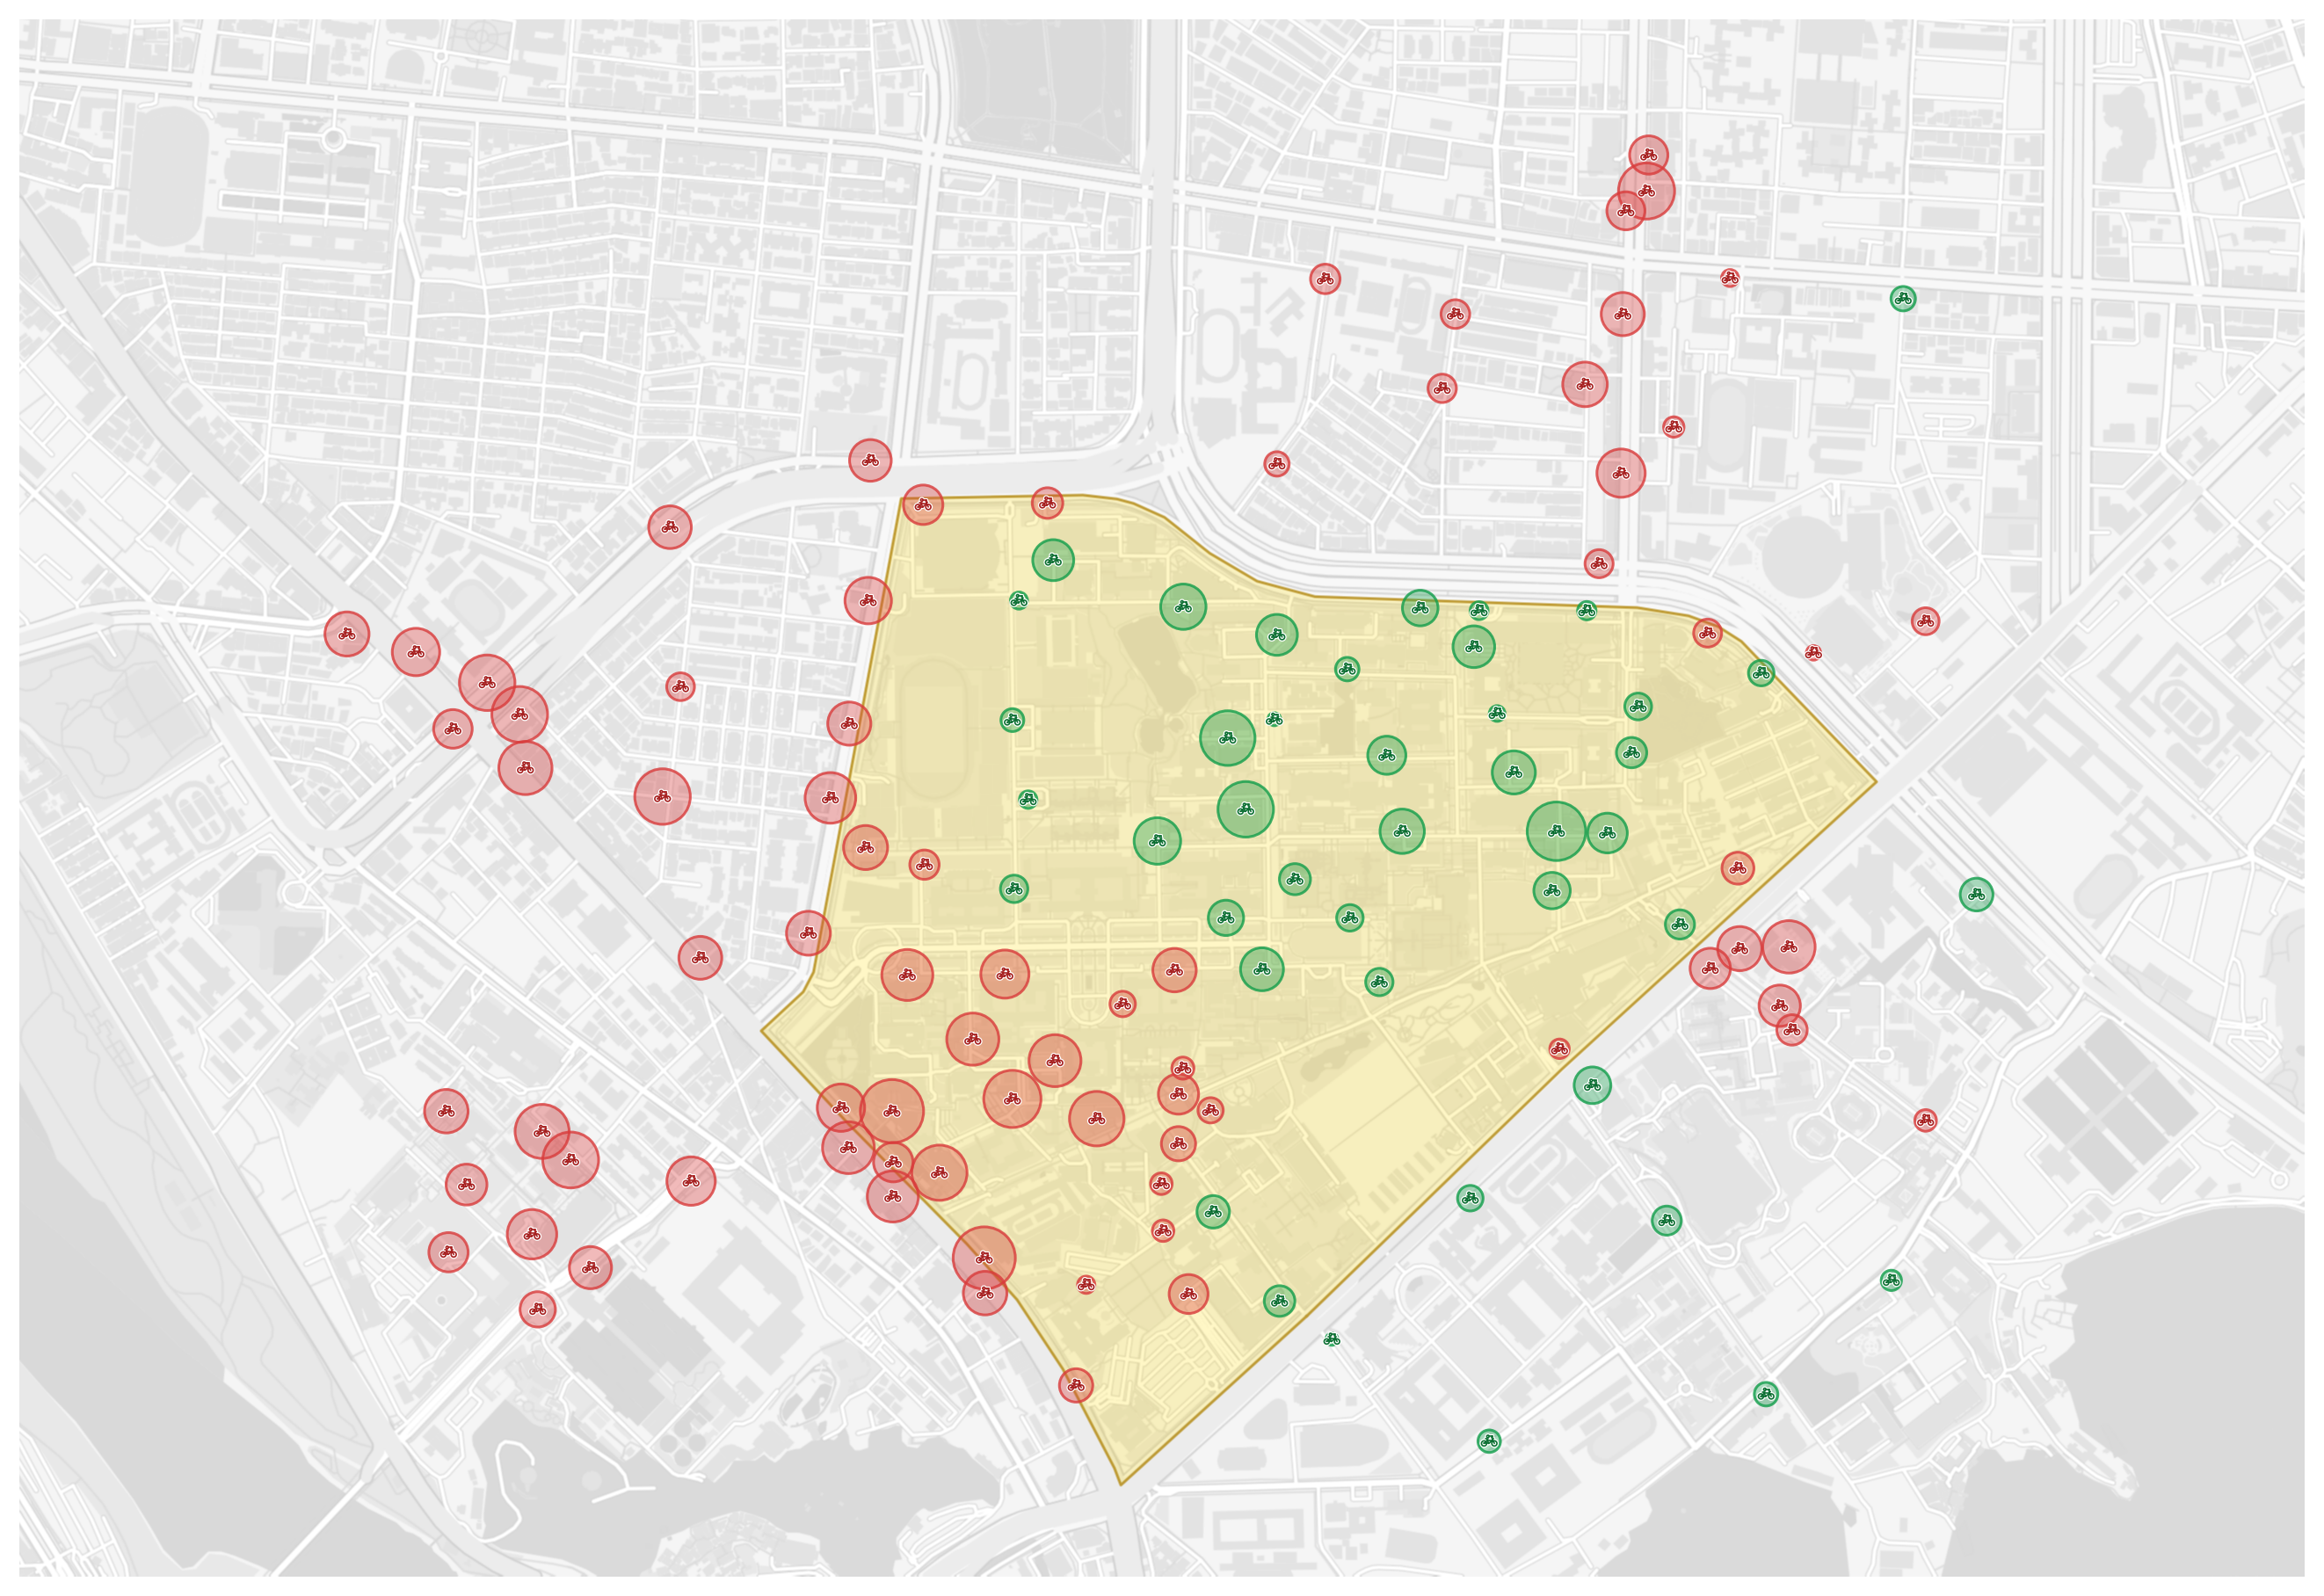

Saved /Users/kdd/NTU/latex/Data_Science_and_Social_Inquiry/project/proposal/contents/figures/map/map7_truncation_09.png (2600 x 1772 px) + map7_truncation_09.pdf


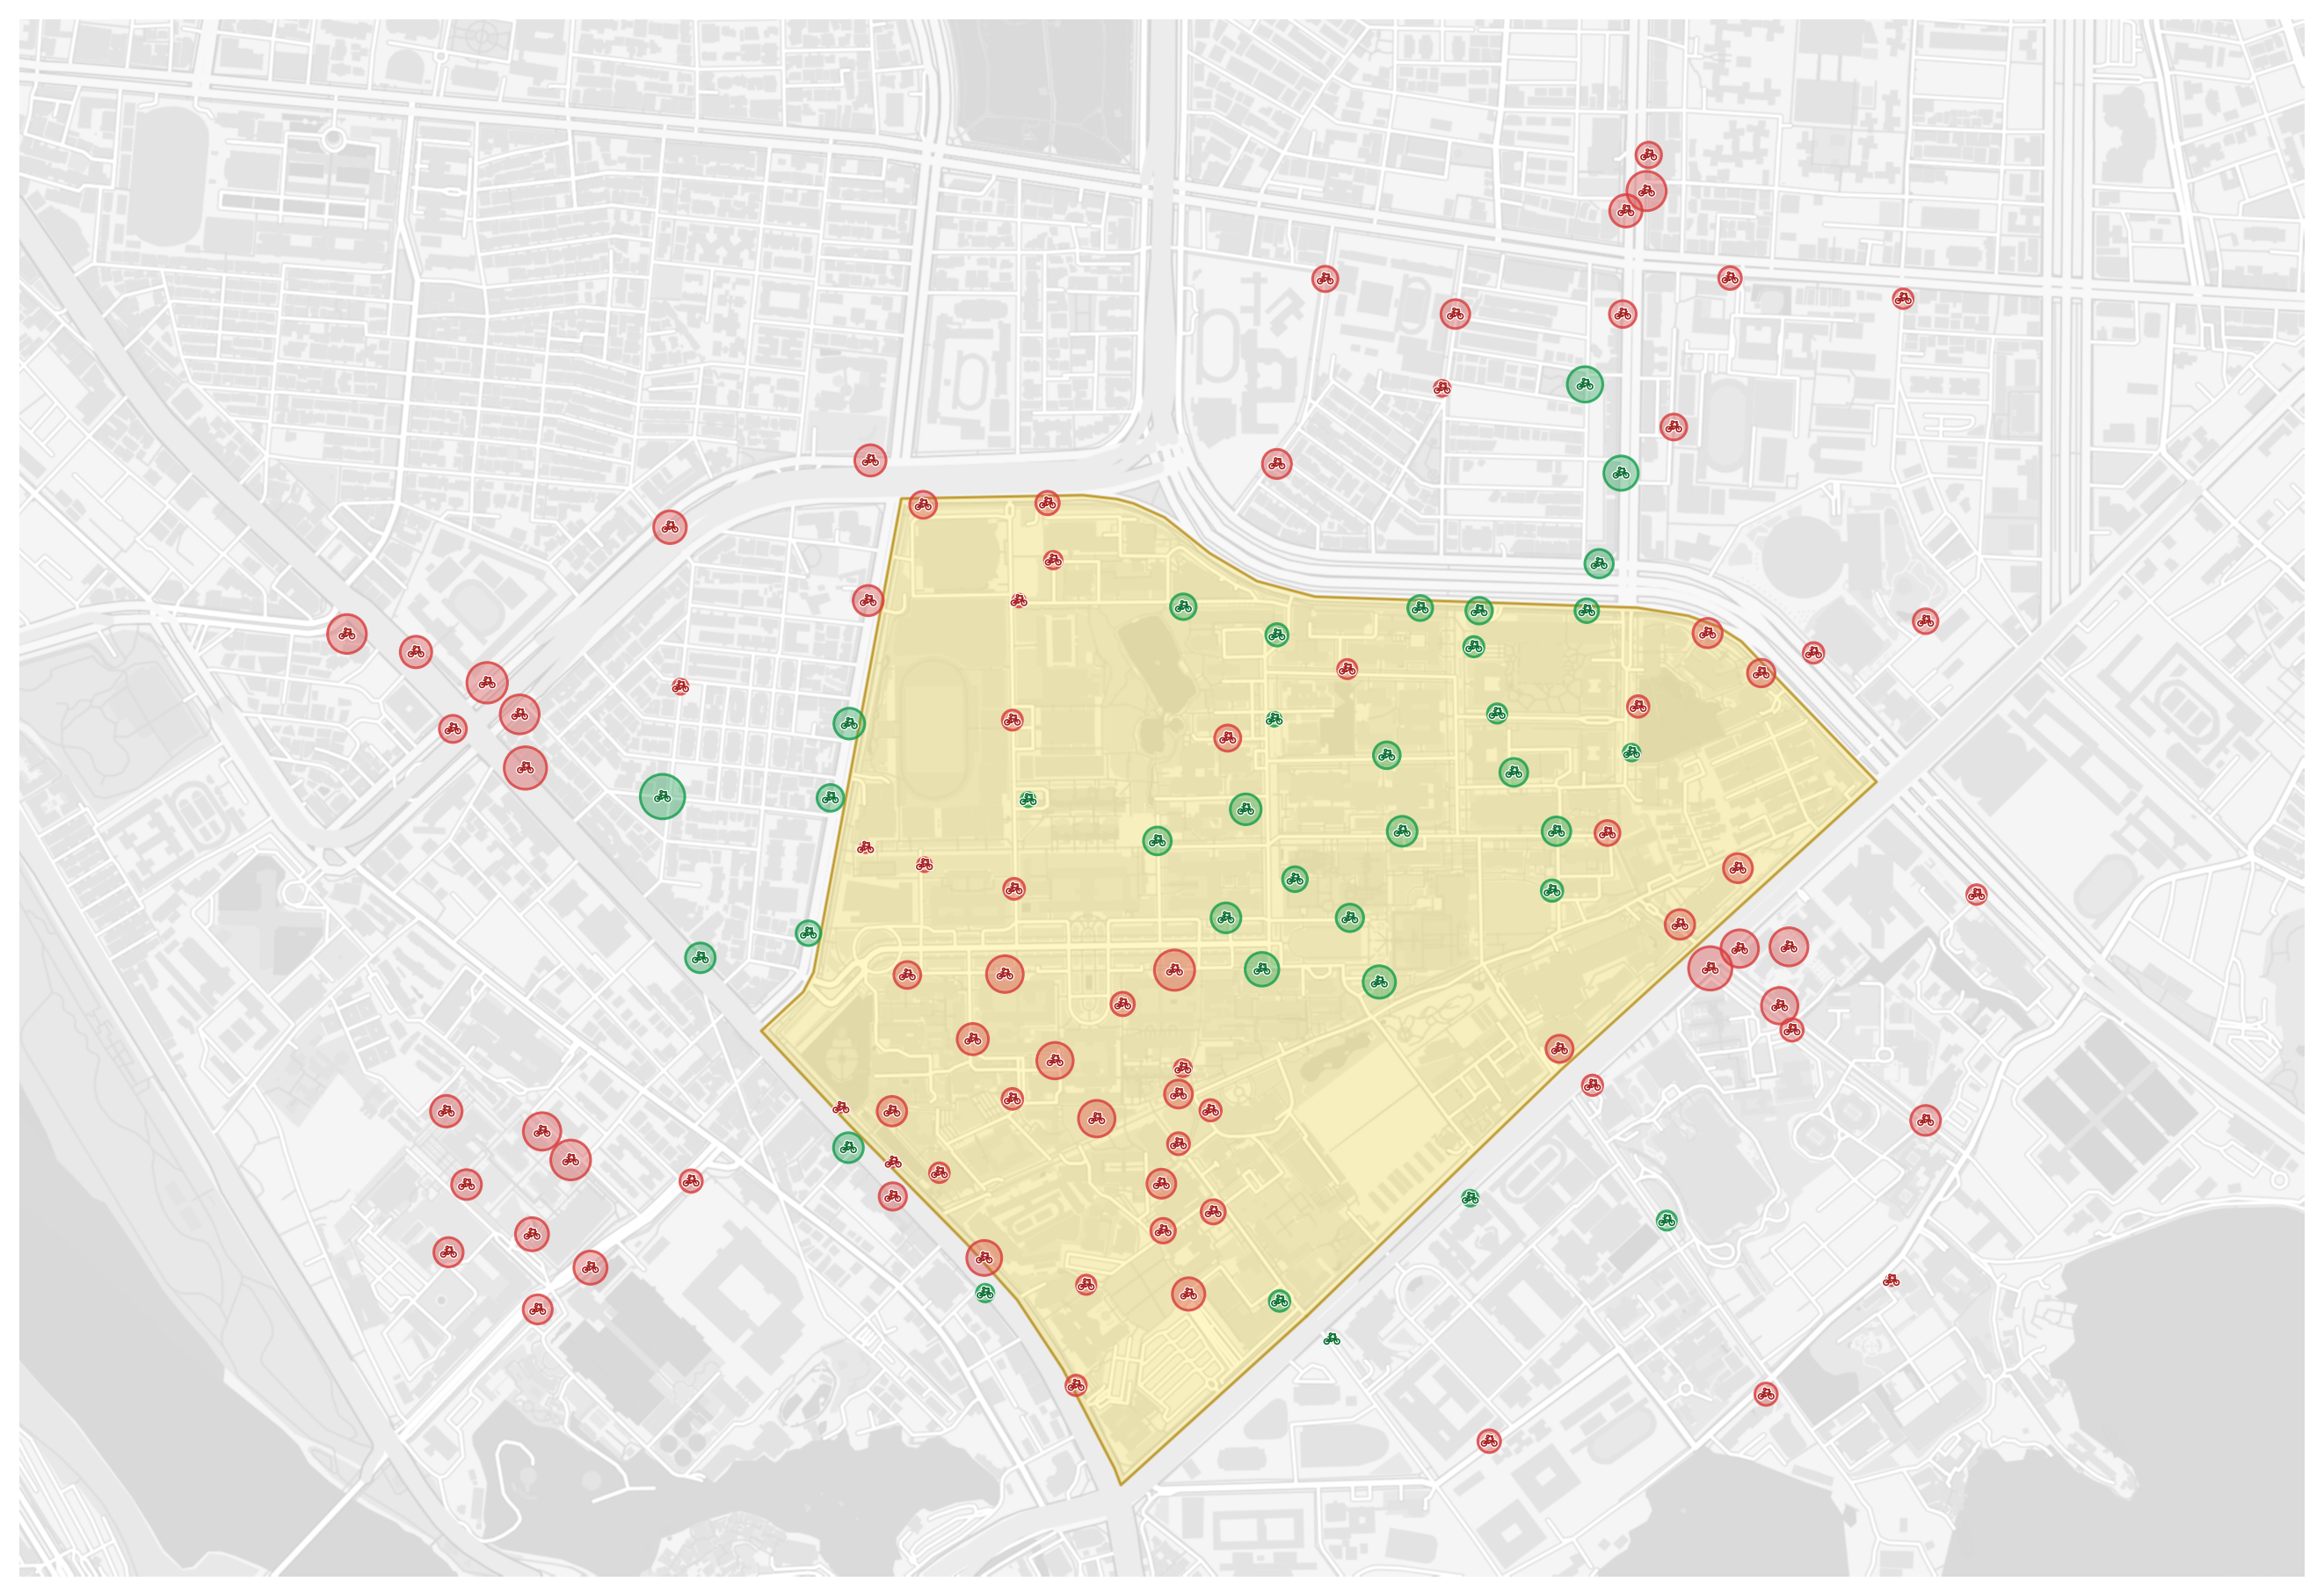

Saved /Users/kdd/NTU/latex/Data_Science_and_Social_Inquiry/project/proposal/contents/figures/map/map7_truncation_12.png (2600 x 1772 px) + map7_truncation_12.pdf


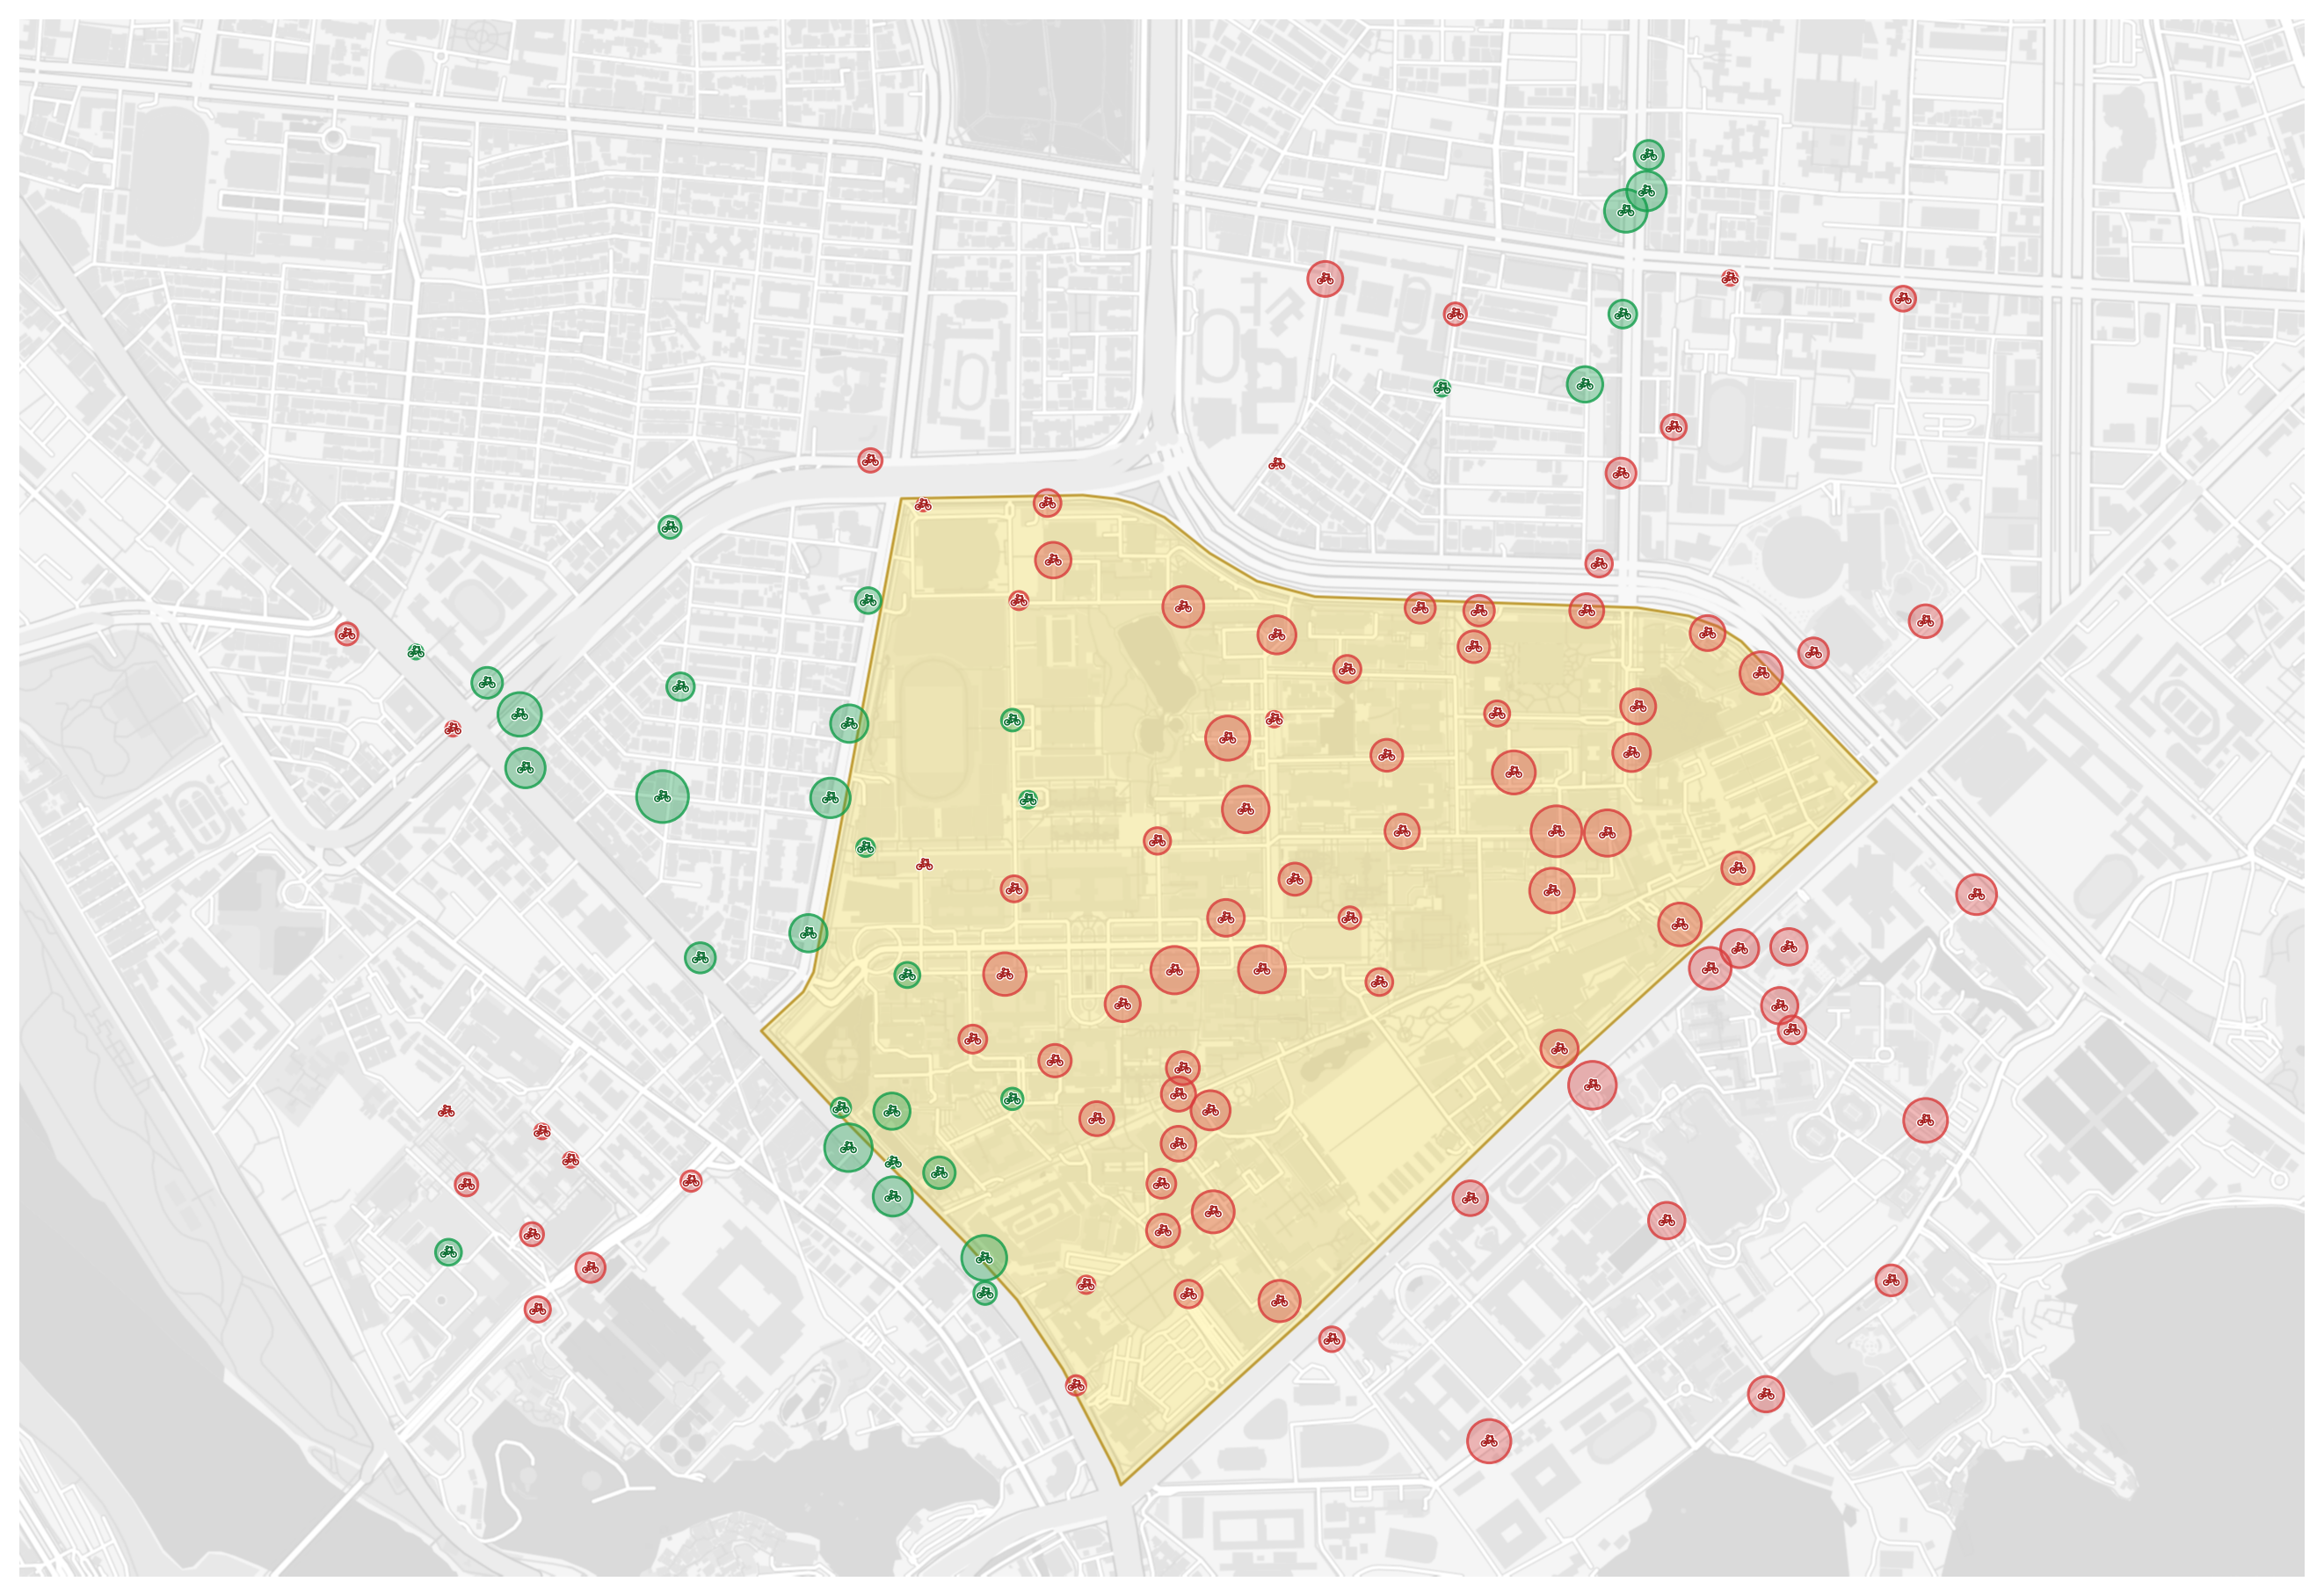

Saved /Users/kdd/NTU/latex/Data_Science_and_Social_Inquiry/project/proposal/contents/figures/map/map7_truncation_17.png (2600 x 1772 px) + map7_truncation_17.pdf


In [4]:
base_layer = Image.open(BASEMAP_HIGHLIGHTED).convert("RGBA")

for h in HOURS:
    sub = sel[sel["hour"] == h].sort_values("unusable_share", ascending=False).reset_index(drop=True)

    fig = plt.figure(figsize=(MAP_W / MAP_DPI, MAP_H / MAP_DPI), dpi=MAP_DPI)
    ax = fig.add_axes([0.0, 0.0, 1.0, 1.0])
    ax.imshow(base_layer, zorder=0)
    ax.set_xlim(0, MAP_W)
    ax.set_ylim(MAP_H, 0)
    ax.set_axis_off()

    for idx, row in enumerate(sub.itertuples(index=False)):
        rad = R_MAX * math.sqrt(row.unusable_share / VMAX_RISK) if VMAX_RISK > 0 else 0.0
        if rad >= 1.5:
            is_full_dom = row.full_share > row.empty_share
            c_fill = COL_GREEN_CIRCLE if is_full_dom else COL_RED_CIRCLE
            z_c = 3.0 + idx * 0.01
            ax.add_patch(Circle((row.px, row.py), rad, facecolor=c_fill, alpha=CIRCLE_FILL_ALPHA, edgecolor="none", zorder=z_c))
            ax.add_patch(Circle((row.px, row.py), rad, facecolor="none", edgecolor=c_fill, alpha=0.80, linewidth=1.0, zorder=z_c + 0.005))

    for row in sub.itertuples(index=False):
        if row.unusable_share <= 0:
            c_icon = COL_ZERO_ICON
        elif row.full_share > row.empty_share:
            c_icon = COL_GREEN_ICON
        else:
            c_icon = COL_RED_ICON
        draw_osm_bicycle_rental_icon(ax, row.px, row.py, ICON_SCALE, c_icon, zorder=7.0)

    out_png = OUT_DIR / f"map7_truncation_{h:02d}.png"
    out_pdf = out_png.with_suffix(".pdf")
    fig.savefig(out_png, dpi=MAP_DPI, pad_inches=0.0)
    fig.savefig(out_pdf, dpi=MAP_DPI, pad_inches=0.0)
    plt.show()
    plt.close(fig)
    chk = Image.open(out_png)
    assert chk.size == (MAP_W, MAP_H), f"Expected {(MAP_W, MAP_H)}, got {chk.size}"
    assert out_pdf.is_file() and out_pdf.stat().st_size > 0
    print(f"Saved {out_png} ({chk.size[0]} x {chk.size[1]} px) + {out_pdf.name}")
